# Databases - Dense series

This tutorial covers `DenseFieldDB`, a field database for dense and regular series, such as hourly weather stations. It holds the same data as `FieldDB` and answers the same queries, but stores it in a wide layout: one row per station and time, with one column per spec, instead of one row per value.

The long layout of the other databases keeps a station, a time, a spec, a flag and row bookkeeping next to every single value. That is what lets them hold replicates and irregular times, but for a station network that reports every variable every hour, the labels outweigh the data many times over. Sharing them across a whole row is what makes the wide layout small, and storing each station's rows together is what makes its series fast to read.

```{seealso}
Check out the {doc}`Databases - Spatial <databases_03_spatial>` tutorial first, which introduces `SitesDB` and setup files.
```

## Notebook setup

For users running this tutorial as a Jupyter Notebook, this cell must be executed first:

In [1]:
import sys
import json
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd

# Install `plans` in `google.colab`.
# Use `pip install plans` for other environments.

if "google.colab" in sys.modules:
    import os
    os.system(f"{sys.executable} -m pip install -q plans")

from plans.databases import DenseFieldDB, FieldDB, HydrologyDenseDB
from plans.datasets.core import TimeSeries

# This avoids warnings related to uninstalled fonts
import logging
# Set the matplotlib font manager logger to only show errors (hides warnings)
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)

# define output folder
OUTPUT_DIR = Path("outputs/databases")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Outputs will be saved to: ./{OUTPUT_DIR}")

Outputs will be saved to: ./outputs\databases


## The data

Lets make two years of hourly data for six stations: air temperature with a daily and a yearly cycle, relative humidity that drops when it warms up, and rain in rare bursts. Gaps are common in station data, so a few weeks of one sensor go missing. The table is wide already, one row per station and hour, as most station files are:

In [2]:
rng = np.random.default_rng(seed=7)  # ensure reproducibility
hours = pd.date_range(start="2023-01-01", end="2024-12-31 23:00", freq="h")
day = np.cos(2 * np.pi * (hours.hour - 15) / 24)
year = np.cos(2 * np.pi * (hours.dayofyear - 15) / 365.25)

stations = gpd.GeoDataFrame(
    data={"name": ["S01", "S02", "S03", "S04", "S05", "S06"], "station_title": ["Coast", "Delta", "Valley", "Hills", "Plateau", "Ridge"]},
    geometry=gpd.points_from_xy(x=[-50.2, -50.9, -51.6, -52.3, -53.0, -53.7], y=[-30.1, -29.8, -29.6, -29.3, -29.0, -28.8]),
    crs="EPSG:4674",
)
frames = []
for k, station in enumerate(stations["name"]):
    tas = 22 - 1.2 * k + 5 * year + 4 * day + rng.normal(scale=1.0, size=len(hours))
    hur = np.clip(0.75 - 0.15 * day + rng.normal(scale=0.05, size=len(hours)), 0.05, 1.0)
    ppt = np.where(rng.random(len(hours)) < 0.04, rng.gamma(shape=0.8, scale=3, size=len(hours)), 0.0)
    frames.append(pd.DataFrame({"site_name": station, "datetime": hours, "TAS_HOURLY": tas.round(1), "HUR_HOURLY": hur.round(2), "PPT_HOURLY": ppt.round(1)}))
hourly = pd.concat(frames, ignore_index=True)

# a broken humidity sensor at S03 for three weeks
broken = (hourly["site_name"] == "S03") & hourly["datetime"].between("2024-06-01", "2024-06-21")
hourly.loc[broken, "HUR_HOURLY"] = np.nan
print(f"{len(hourly)} station-hours, {int(hourly[['TAS_HOURLY', 'HUR_HOURLY', 'PPT_HOURLY']].notna().sum().sum())} values")
hourly.head()

105264 station-hours, 315311 values


,site_name,datetime,TAS_HOURLY,HUR_HOURLY,PPT_HOURLY
0,S01,2023-01-01 00:00:00,24.0,0.85,0.0
1,S01,2023-01-01 01:00:00,23.7,0.80,0.0
2,S01,2023-01-01 02:00:00,22.7,0.87,0.0
3,S01,2023-01-01 03:00:00,22.0,0.95,0.0
4,S01,2023-01-01 04:00:00,22.5,0.92,0.0


## Creating the database

The setup is the same as for any sites database. Spec names become the column names of `records`, and the specs must all share one timestep, since a wide row is one time step. A `scale` turns values with one decimal into whole numbers, which SQLite stores in fewer bytes:

In [3]:
def make_spec(name, abstract, variable, statistic, scale):
    # one hourly spec
    return {
        "name": name,
        "abstract": abstract,
        "method": "synthetic",
        "timestep": "1h",
        "extent": "station",
        "scale": scale,
        "offset": 0,
        "start": "2023-01-01",
        "end": None,
        "variable_name": variable,
        "statistic_name": statistic,
        "source_name": "INMET",
    }


specs = [
    make_spec("TAS_HOURLY", "Hourly air temperature", "surface air temperature", "instant", 10),
    make_spec("HUR_HOURLY", "Hourly relative humidity", "surface air relative humidity", "instant", 100),
    make_spec("PPT_HOURLY", "Hourly rainfall", "precipitation", "sum", 10),
]
file_specs = OUTPUT_DIR / "hourly_specs.json"
_ = file_specs.write_text(json.dumps(specs, indent=2), encoding="utf-8")
file_stations = OUTPUT_DIR / "hourly_stations.gpkg"
stations.to_file(filename=file_stations, driver="GPKG")

As a file, the setup reads:

`````{tab-set}
:sync-group: setup

````{tab-item} TOML
:sync: toml

```toml
[database]
path = "outputs/databases/hourly_dense.gpkg"

[specs]
path = "outputs/databases/hourly_specs.json"

[spatial]
file = "outputs/databases/hourly_stations.gpkg"
```
````

````{tab-item} JSON
:sync: json

```json
{
  "database": {"path": "outputs/databases/hourly_dense.gpkg"},
  "specs": {"path": "outputs/databases/hourly_specs.json"},
  "spatial": {"file": "outputs/databases/hourly_stations.gpkg"}
}
```
````
`````

Here it is passed as a dict. The `records` table comes out with one column per spec, and a `record_flags` table next to it:

In [4]:
config = {
    "database": {"path": str(OUTPUT_DIR / "hourly_dense.gpkg")},
    "specs": {"path": str(file_specs)},
    "spatial": {"file": str(file_stations), "columns_map": {"station_title": "station_title"}},
}
db = DenseFieldDB(name="Hourly")
db.new(config=config, overwrite=True)
print(db.inspect_schema(table="records", quiet=True))

[Hourly]
  records  (0 rows)
    site_id              INTEGER
    datetime             INTEGER
    tas_hourly           REAL
    hur_hourly           REAL
    ppt_hourly           REAL



## Loading

The `.insert_wide()` method takes the wide table as it is: `datetime`, the station by `site_name` or `site_id`, and one column per spec, named after it. It is the fast path for bulk loads. Empty cells store nothing, so the broken sensor leaves no trace but the gap. Values outside the domain of their variable become `suspect`, as everywhere in `plans`:

In [5]:
db.insert_wide(dataframe=hourly)
db.query_sql(sql="SELECT COUNT(*) AS rows FROM records")

,rows
0,105264


Only flags other than `regular` take space, as rows of `record_flags`. A value is `regular` unless that table says otherwise, so this clean load added none. One spec at a time still goes through `.insert_records()`, as in the long databases. Here, two readings come late from a manual check at `S01`, one of them a humidity above 100%:

In [6]:
late = pd.DataFrame({"site_name": "S01", "datetime": ["2025-01-01 00:00", "2025-01-01 01:00"], "value": [0.82, 1.04]})
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    db.insert_records(dataframe=late, spec_name="HUR_HOURLY", flag=1)
print(*[w.message for w in caught], sep="\n")
db.query_sql(sql="SELECT * FROM record_flags")

1 value(s) of HUR_HOURLY outside [0U1] flagged suspect


,spec_id,site_id,datetime,flag_value
0,2,1,1735693200,2


A replicate has nowhere to go in a wide row, so a second value for the same spec, station and time is refused, and the first one stays:

In [7]:
try:
    db.insert_records(dataframe=late.head(1).assign(value=0.5), spec_name="HUR_HOURLY", flag=1)
except ValueError as error:
    print(error)

1 replicated value(s) in hur_hourly; a value already exists for that site and time


## Querying

`.query_records()` takes the same keys and returns the same long table as in `FieldDB`, so code written for one works on the other. Rows are stored by station and then time, so a station's series is read straight from its block:

In [8]:
df = db.query_records(query_dict={"site_name": "S03", "spec_name": "HUR_HOURLY", "start": "2024-05-31 22:00", "end": "2024-06-21 02:00"})
df[["datetime", "spec_name", "value", "flag_value", "site_id"]]

,datetime,spec_name,value,flag_value,site_id
0,2024-05-31 22:00:00+00:00,HUR_HOURLY,0.73,1,3
1,2024-05-31 23:00:00+00:00,HUR_HOURLY,0.86,1,3
2,2024-06-21 01:00:00+00:00,HUR_HOURLY,0.94,1,3
3,2024-06-21 02:00:00+00:00,HUR_HOURLY,0.88,1,3


Flags filter as usual, and `wide=True` returns one column per spec:

In [9]:
print(db.query_records(query_dict={"flag_value": 2})[["datetime", "spec_name", "value", "flag_value"]])
db.query_records(query_dict={"site_name": "S01", "start": "2024-07-01", "end": "2024-07-01 03:00", "wide": True})

                   datetime   spec_name  value  flag_value
0 2025-01-01 01:00:00+00:00  HUR_HOURLY   1.04           2


spec_name,TAS_HOURLY,HUR_HOURLY,PPT_HOURLY
site_id,1,1,1
datetime,,,
2024-07-01 00:00:00+00:00,14.0,0.82,0.0
2024-07-01 01:00:00+00:00,13.2,0.98,0.0
2024-07-01 02:00:00+00:00,12.5,0.75,0.0
2024-07-01 03:00:00+00:00,13.4,0.93,0.0


A query returns a plain `DataFrame`, ready for the analysis classes of `plans`. `TimeSeries` takes timestamps without a time zone, while database times are UTC, so the zone is dropped first:

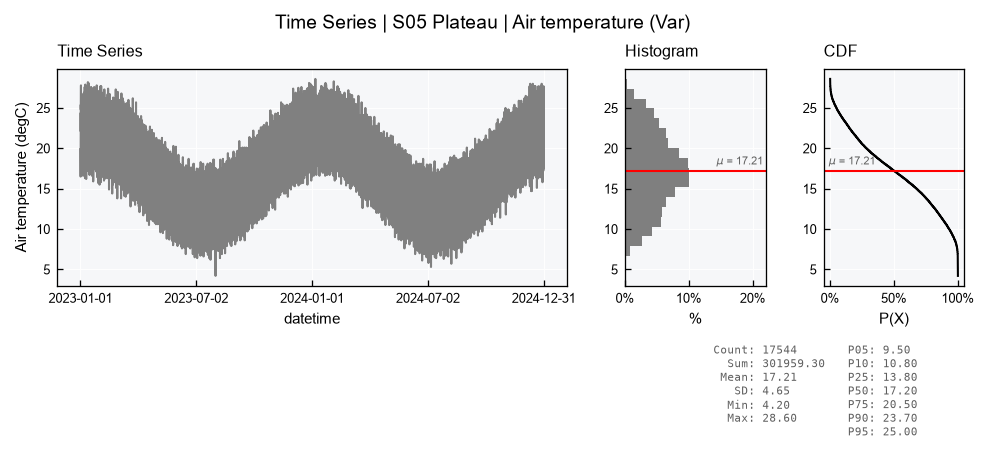

In [10]:
df = db.query_records(query_dict={"site_name": "S05", "spec_name": "TAS_HOURLY"})
df["datetime"] = df["datetime"].dt.tz_localize(None)

ts = TimeSeries(name="S05 Plateau", alias="S05")
ts.varname = "Air temperature"
ts.units = "degC"
ts.set_data(input_df=df, input_dtfield="datetime", input_varfield="value")
ts.view_specs["ylabel"] = f"Air temperature ({ts.units})"
ts.view()

## Catchments: `HydrologyDenseDB`

For river gauges with their catchments, `HydrologyDenseDB` joins this layout with `HydrologyDB`: the setup takes the optional `catchments` section, and the catchment methods work as in the {doc}`Databases - Hydrology <databases_05_hydrology>` tutorial. Lets say three of the stations are also gauges, with drawn catchments, and hold daily streamflow and rain next to a monthly rain product from another source. Specs may mix timesteps:

In [11]:
gauge_specs = [
    dict(make_spec("Q_DAILY", "Daily mean streamflow", "streamflow", "mean", 100), timestep="1D"),
    dict(make_spec("PPT_DAILY", "Daily rainfall", "precipitation", "sum", 10), timestep="1D"),
    dict(make_spec("PPT_MONTHLY_CHIRPS", "Monthly rainfall from CHIRPS", "precipitation", "sum", 10), timestep="1M", source_name="CHIRPS v2.0"),
]
file_gauge_specs = OUTPUT_DIR / "gauges_specs.json"
_ = file_gauge_specs.write_text(json.dumps(gauge_specs, indent=2), encoding="utf-8")

catchments = gpd.GeoDataFrame(
    data={"name": ["S01", "S02", "S03"], "area_km2": [420.0, 260.0, 130.0]},
    geometry=[point.buffer(0.15) for point in stations.geometry[:3]],
    crs="EPSG:4674",
)
file_catchments = OUTPUT_DIR / "gauges_catchments.gpkg"
catchments.to_file(filename=file_catchments, driver="GPKG")

hdb = HydrologyDenseDB(name="Gauges")
hdb.new(
    config={
        "database": {"path": str(OUTPUT_DIR / "gauges_dense.gpkg")},
        "specs": {"path": str(file_gauge_specs)},
        "spatial": {"file": str(file_stations), "columns_map": {"station_title": "station_title"}},
        "catchments": {"file": str(file_catchments), "columns_map": {"area_km2": "area_km2"}},
    },
    overwrite=True,
)
print("Missing catchments:", hdb.missing_catchments())
print(hdb.inspect_schema(table="records", quiet=True))

Missing catchments: ['S04', 'S05', 'S06']
[Gauges]
  records  (0 rows)
    site_id              INTEGER
    datetime             INTEGER
    q_daily              REAL
    ppt_daily            REAL
    ppt_monthly_chirps   REAL



Each spec loads on its own, in any order. The daily series go in bulk with `.insert_wide()`. The monthly product arrives later and goes in with `.insert_records()`, stamped on the first day of each month at 00:00, so it fills a cell of the daily rows instead of adding rows of its own:

In [12]:
gauges = hourly[hourly["site_name"].isin(["S01", "S02", "S03"])]
daily = gauges.groupby(["site_name", gauges["datetime"].dt.floor("D")])["PPT_HOURLY"].sum().reset_index(name="PPT_DAILY")
area = catchments.set_index("name")["area_km2"]
# streamflow: rain over the catchment, released over about two weeks
daily["Q_DAILY"] = (
    daily.groupby("site_name")["PPT_DAILY"].transform(lambda p: p.ewm(span=14).mean())
    * daily["site_name"].map(area) * 1e3 * 0.4 / 86400
).round(2)
hdb.insert_wide(dataframe=daily)

monthly = daily.groupby(["site_name", daily["datetime"].dt.to_period("M").dt.start_time])["PPT_DAILY"].sum() * 1.05
monthly = monthly.round(1).reset_index().rename(columns={"PPT_DAILY": "value"})
hdb.insert_records(dataframe=monthly, spec_name="PPT_MONTHLY_CHIRPS", flag=1)
hdb.query_records(query_dict={"site_name": "S02", "start": "2024-01-30", "end": "2024-02-02", "wide": True})

spec_name,Q_DAILY,PPT_DAILY,PPT_MONTHLY_CHIRPS
site_id,2,2,2
datetime,,,
2024-01-30 00:00:00+00:00,2.80,5.1,NaN
2024-01-31 00:00:00+00:00,2.51,0.5,NaN
2024-02-01 00:00:00+00:00,3.25,6.7,78.6
2024-02-02 00:00:00+00:00,3.44,3.9,NaN


The monthly column is empty on all but one row a month. Each empty cell costs about one byte, so a few monthly or yearly specs next to daily ones cost little, while a database made mostly of them is better kept in the long layout.

In [13]:
hdb.close()

## How much smaller

Lets load the same table into a `FieldDB`, one spec at a time, and compare the two files after compacting them:

In [14]:
long_config = dict(config, database={"path": str(OUTPUT_DIR / "hourly_long.gpkg")})
long_db = FieldDB(name="Hourly long")
long_db.new(config=long_config, overwrite=True)
with long_db.transaction():
    for spec in ["TAS_HOURLY", "HUR_HOURLY", "PPT_HOURLY"]:
        part = hourly[["site_name", "datetime", spec]].rename(columns={spec: "value"})
        long_db.insert_records(dataframe=part, spec_name=spec, flag=1)

sizes = {}
for label, base in [("FieldDB (long)", long_db), ("DenseFieldDB (wide)", db)]:
    base.execute_sql(sql="VACUUM")
    sizes[label] = Path(base.file_db).stat().st_size / 1e6
values = long_db.query_sql(sql="SELECT COUNT(*) AS n FROM records")["n"].iloc[0]
pd.DataFrame({"MB": sizes, "bytes per value": {k: v * 1e6 / values for k, v in sizes.items()}}).round(2)

,MB,bytes per value
FieldDB (long),21.93,69.55
DenseFieldDB (wide),2.04,6.47


Much of the long file goes to its three indexes on `records`, and the rest to the labels repeated on every value. At this size, both answer queries quickly; the gap in speed grows with the file. On a real network of 600 hourly stations over 26 years, the wide layout took 3.9 GB against 33 GB for the long layout without any indexes, and read a station in a fraction of a second instead of over a minute.

## Limits

The wide layout pays for its size with the flexibility of the long one:

- specs may mix timesteps, but a coarse value leaves empty cells on the rows between two values, about one byte each: a few yearly or monthly specs next to daily ones cost little, while many of them, or monthly next to hourly, are better kept in a separate database;
- there are no replicates, so it does not suit lab results or repeated readings;
- specs cannot be added after creation yet;
- `records` is a `WITHOUT ROWID` table, which GDAL cannot open: QGIS shows the stations and the catalogs, but reads records only through SQL;
- one variable over all stations and times reads the whole table, and is built in memory as a long table, so large files are best queried by station or time.

Each spec loads on its own, in any order: `.insert_records()` fills its column on existing rows and adds rows where none exist. For sparse or irregular data, or anything with replicates, the long `FieldDB` remains the better fit.

In [15]:
long_db.close()
db.close()